# 06 · Gradient boosting and XGBoost

**Random forests** average independent deep trees (reduces variance).
**Boosting** adds *shallow* trees **sequentially**, each one fitted to the errors of the ensemble so far (reduces bias):

$$F_m(x) = F_{m-1}(x) + \eta \cdot h_m(x), \qquad h_m \approx \text{fit to the negative gradient of the loss (for MSE: the residuals)}$$

The learning rate $\eta$ shrinks each step. Smaller $\eta$ + more trees ≈ better but slower. The number of trees is chosen by **early stopping** on a validation set.

XGBoost (2014) made this fast and regularised (L1/L2 on leaf weights, second-order gradients, sparsity handling). It and its cousins (LightGBM, CatBoost) dominate tabular prediction.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

# One consistent, colour-blind-friendly style for every notebook.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY = "#a3a29c"
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.8,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pd.set_option("display.precision", 4)

In [2]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error as rmse

X, y = fetch_california_housing(return_X_y=True, as_frame=True)
X_trval, X_test, y_trval, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=0.2, random_state=SEED)
print(len(X_train), len(X_val), len(X_test))

13209 3303 4128


## 1. Boosting from scratch in 10 lines

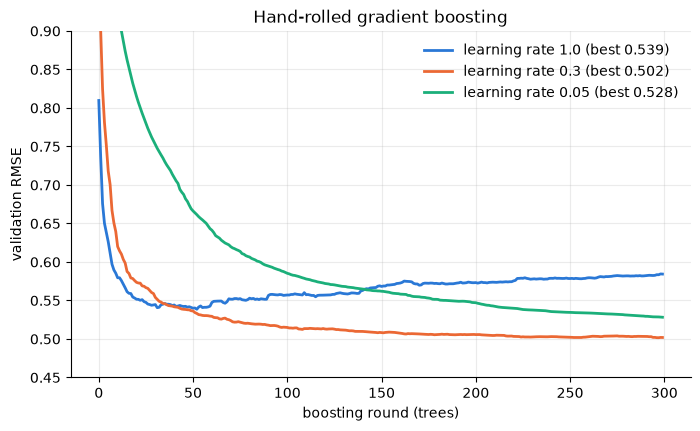

In [3]:
from sklearn.tree import DecisionTreeRegressor

def boost(lr, n_rounds=300, depth=3):
    pred_tr = np.full(len(y_train), y_train.mean())
    pred_va = np.full(len(y_val), y_train.mean())
    curve = []
    for _ in range(n_rounds):
        residual = y_train - pred_tr                       # negative gradient of squared error
        tree = DecisionTreeRegressor(max_depth=depth).fit(X_train, residual)
        pred_tr += lr * tree.predict(X_train)
        pred_va += lr * tree.predict(X_val)
        curve.append(rmse(y_val, pred_va))
    return curve

fig, ax = plt.subplots()
for k, lr in enumerate([1.0, 0.3, 0.05]):
    c = boost(lr)
    ax.plot(c, color=PALETTE[k], label=f"learning rate {lr} (best {min(c):.3f})")
ax.set_xlabel("boosting round (trees)"); ax.set_ylabel("validation RMSE"); ax.set_ylim(0.45, 0.9); ax.legend()
ax.set_title("Hand-rolled gradient boosting")
plt.show()

A large learning rate (1.0) converges fast and then overfits. Smaller rates learn more slowly; 0.05 is still improving after 300 trees and, given enough of them, typically ends at least as low as 0.3. That is why real libraries pair a small learning rate with **early stopping** and thousands of trees: the core trade-off of every boosting library.

## 2. XGBoost with early stopping

In [4]:
import xgboost as xgb

model = xgb.XGBRegressor(
    n_estimators=5000,          # upper bound; early stopping picks the real number
    learning_rate=0.05,
    max_depth=6,                # tree depth (XGBoost grows level-wise)
    min_child_weight=1,         # min sum of hessian in a leaf ~ min samples per leaf
    subsample=0.8,              # row sampling per tree
    colsample_bytree=0.8,       # feature sampling per tree
    reg_lambda=1.0,             # L2 on leaf weights
    tree_method="hist",
    early_stopping_rounds=200,
    eval_metric="rmse",
    random_state=SEED, n_jobs=-1,
)
model.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_val, y_val)], verbose=False)
print(f"best iteration: {model.best_iteration}, val RMSE: {model.best_score:.4f}")
print(f"test RMSE: {rmse(y_test, model.predict(X_test)):.4f}")

best iteration: 1689, val RMSE: 0.4630
test RMSE: 0.4397


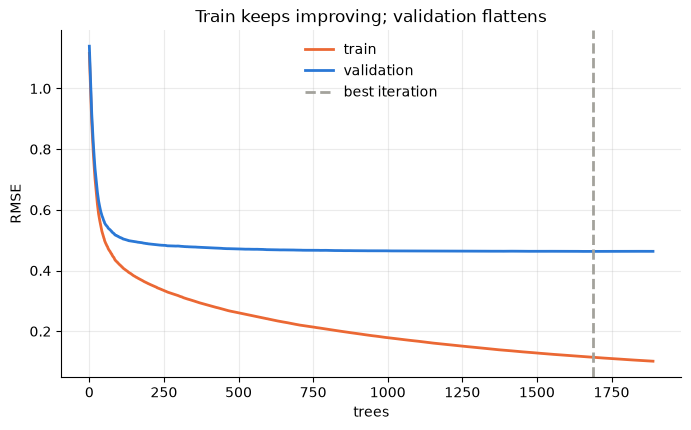

In [5]:
res = model.evals_result()
fig, ax = plt.subplots()
ax.plot(res["validation_0"]["rmse"], label="train", color=PALETTE[1])
ax.plot(res["validation_1"]["rmse"], label="validation", color=PALETTE[0])
ax.axvline(model.best_iteration, color=GREY, ls="--", label="best iteration")
ax.set_xlabel("trees"); ax.set_ylabel("RMSE"); ax.legend(); ax.set_title("Train keeps improving; validation flattens")
plt.show()

**Important:** after early stopping on the validation set, its score is slightly optimistic. Report the untouched test set (or use CV).
For the final model, a common recipe is to refit on train+val with `n_estimators ≈ best_iteration × (1 + share of extra data)`.

## 3. The parameters that matter (in rough order)

| Param | What it does | Typical search range |
|---|---|---|
| `learning_rate` | step size; lower is better if you can afford more trees | 0.01–0.1 (fix it, then early-stop) |
| `max_depth` | interaction order / complexity | 3–10 |
| `min_child_weight` | minimum leaf "size"; higher = more conservative | 1–100 (log) |
| `subsample`, `colsample_bytree` | randomness, decorrelates trees | 0.5–1.0 |
| `reg_lambda`, `reg_alpha` | L2/L1 on leaf values | 1e-3–10 (log) |
| `gamma` | min loss reduction to split | 0–5 |

Objectives: `reg:squarederror`, `reg:absoluteerror`, `reg:quantileerror`, `binary:logistic`, `multi:softprob`, `rank:ndcg`, `count:poisson`, `reg:tweedie` …

## 4. Classification with native categorical support

Adult census income (48k people, predict income > $50k). XGBoost can use pandas `category` columns directly with `enable_categorical=True`.

In [6]:
from sklearn.datasets import fetch_openml
from sklearn.metrics import roc_auc_score, log_loss

adult = fetch_openml("adult", version=2, as_frame=True)
Xa = adult.data
ya = (adult.target == ">50K").astype(int)
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(Xa, ya, test_size=0.2, stratify=ya, random_state=SEED)
Xa_tr, Xa_va, ya_tr, ya_va = train_test_split(Xa_tr, ya_tr, test_size=0.2, stratify=ya_tr, random_state=SEED)
n_cat = (Xa.dtypes == "category").sum()
print(f"{n_cat} categorical + {Xa.shape[1] - n_cat} numeric columns | positive rate {ya.mean():.2f}")

clf = xgb.XGBClassifier(n_estimators=3000, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
                        enable_categorical=True, tree_method="hist", max_cat_to_onehot=1,
                        early_stopping_rounds=100, eval_metric="logloss", random_state=SEED, n_jobs=-1)
clf.fit(Xa_tr, ya_tr, eval_set=[(Xa_va, ya_va)], verbose=False)
p = clf.predict_proba(Xa_te)[:, 1]
print(f"trees: {clf.best_iteration} | test AUC {roc_auc_score(ya_te, p):.4f} | log loss {log_loss(ya_te, p):.4f}")

8 categorical + 6 numeric columns | positive rate 0.24


trees: 260 | test AUC 0.9293 | log loss 0.2755


## 5. Feature importance types
- `weight`: how often a feature is used to split (misleading)
- `gain`: average loss reduction when used (better)
- For trustworthy attributions use SHAP (`pred_contribs=True` in XGBoost, or the `shap` library, notebook 12).

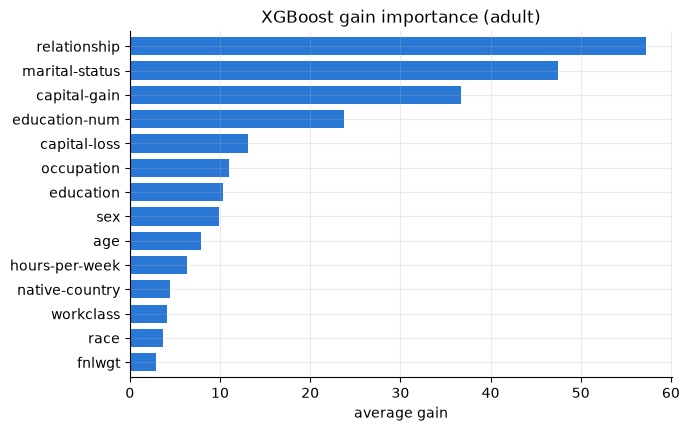

In [7]:
gain = pd.Series(clf.get_booster().get_score(importance_type="gain")).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
gain.plot.barh(ax=ax, color=PALETTE[0], width=0.75); ax.set_xlabel("average gain"); ax.set_title("XGBoost gain importance (adult)")
plt.show()

## Takeaways
- Boosting = sequential shallow trees fitted to residuals; `learning_rate` × `n_estimators` is the key trade-off.
- **Always use early stopping** with a validation set (or `xgb.cv`).
- Tune `max_depth`/`min_child_weight` first, then sampling, then regularisation (notebook 09 uses Optuna).
- Match the `objective` to your metric (MAE → `reg:absoluteerror`, quantiles → `reg:quantileerror`).